### Imports

In [1]:
import numpy as np
from PIL import Image
import pickle
import matplotlib.pyplot as plt
from lewm.paths import repo_path

### Image Processing Functions

In [32]:
def bytes_to_image(frame):
    image = np.frombuffer(frame, dtype=np.uint8)
    image = image.reshape((64, 64, 3))
    image = Image.fromarray(image)

    return image


def image_to_bytes(image):
    if image.dtype == np.float32:
        image *= 255
        image = image.astype(np.uint8)

    image = image.flatten()
    image = bytearray(image)

    return image


def load_image_bytes(filename):
    image_bytes = None

    with open(filename, 'rb') as f:
        image_bytes = pickle.load(f)[0]

    return image_bytes


def save_image_bytes(filename, image_bytes):
    image_bytes = [image_bytes]

    with open(filename, 'wb') as f:
        pickle.dump(image_bytes, f)

    return

### Conversion Work

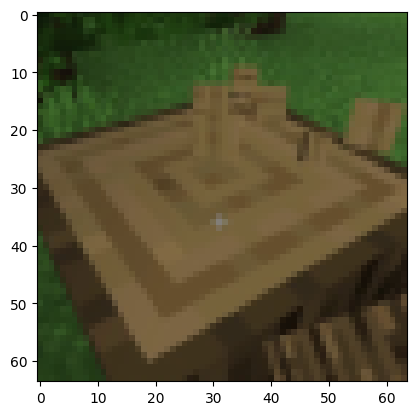

In [35]:
goal_file = repo_path("artifacts/fixtures/goal_tree_chop.pkl")

with open(goal_file, "rb") as file:
    goal_frame = pickle.load(file)[0]

plt.imshow(bytes_to_image(goal_frame));

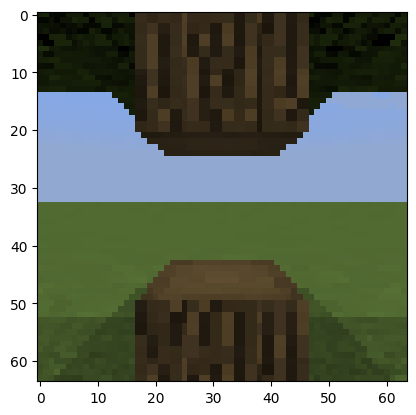

In [36]:
goal_obs_png_path = "../Malmo/Minecraft/run/screenshots/2026-11-18_14.38.49.png"
goal_obs_pkl_path = "../artifacts/fixtures/goal_tree_chop_superflat.pkl"

# Test saving process
goal_obs = plt.imread(goal_obs_png_path) # Read png image
goal_obs = image_to_bytes(goal_obs) # Convert to bytes
save_image_bytes(goal_obs_pkl_path, goal_obs) # Save image bytes

# Test loading process
goal_obs = load_image_bytes(goal_obs_pkl_path) # Load same image bytes
goal_obs = bytes_to_image(goal_obs) # Convert to image
plt.imshow(goal_obs);